In [27]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Dropout
from tensorflow.keras.utils import to_categorical

In [28]:
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [29]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [30]:
x_train=x_train.astype("float32")/255.0
x_test=x_test.astype("float32")/255.0

In [31]:
x_train_img=x_train.reshape(-1,28,28)
x_test_img=x_test.reshape(-1,28,28)

In [32]:
x_train_img

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.

In [33]:
y_train_cat=to_categorical(y_train,10)
y_test_cat=to_categorical(y_test,10)

In [34]:
perceptron=Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10,activation="softmax")
])

In [35]:
perceptron.compile(optimizer='sgd',loss='categorical_crossentropy',metrics=["accuracy"])

In [36]:
history_percp = perceptron.fit(x_train_img, y_train_cat, epochs=5, batch_size=32, validation_split=0.1)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8050 - loss: 0.8125 - val_accuracy: 0.9007 - val_loss: 0.4473
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8766 - loss: 0.4754 - val_accuracy: 0.9122 - val_loss: 0.3646
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8872 - loss: 0.4187 - val_accuracy: 0.9162 - val_loss: 0.3321
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8932 - loss: 0.3903 - val_accuracy: 0.9173 - val_loss: 0.3135
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8979 - loss: 0.3725 - val_accuracy: 0.9203 - val_loss: 0.3014


In [37]:
acc_percp=perceptron.evaluate(x_test_img,y_test_cat,verbose=0)[1]
acc_percp

0.9068999886512756

In [38]:
ann=Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128,activation="relu"),
    Dense(64,activation="relu"),
    Dense(10,activation="softmax")
])

In [39]:
ann.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [40]:
ann.fit(
    x_train_img,
    y_train_cat,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9255 - loss: 0.2531 - val_accuracy: 0.9652 - val_loss: 0.1121
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9676 - loss: 0.1063 - val_accuracy: 0.9757 - val_loss: 0.0837
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9771 - loss: 0.0732 - val_accuracy: 0.9717 - val_loss: 0.0881
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9830 - loss: 0.0550 - val_accuracy: 0.9788 - val_loss: 0.0813
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9855 - loss: 0.0436 - val_accuracy: 0.9760 - val_loss: 0.0850


In [41]:
acc_ann=ann.evaluate(x_test_img,y_test_cat,verbose=0)[1]
acc_ann

0.9782999753952026

In [42]:
x_train_cnn=x_train.reshape(-1,28,28,1)
x_test_cnn=x_test.reshape(-1,28,28,1)

In [43]:
cnn=Sequential([
    Conv2D(32,kernel_size=(3,3),activation='relu',input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)), 
    Conv2D(64,kernel_size=(3,3),activation='relu'),
    MaxPooling2D(pool_size=(2,2)), 
    Flatten(), 
    Dense(128,activation="relu"),
    Dropout(0.5),
    Dense(10,activation="softmax")
])

In [44]:
cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [45]:
history_cnn=cnn.fit(x_train_cnn,y_train_cat,epochs=5,batch_size=32,validation_split=0.1)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 25s 13ms/step - accuracy: 0.9281 - loss: 0.2367 - val_accuracy: 0.9875 - val_loss: 0.0498
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - accuracy: 0.9733 - loss: 0.0911 - val_accuracy: 0.9885 - val_loss: 0.0432
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 24s 14ms/step - accuracy: 0.9801 - loss: 0.0676 - val_accuracy: 0.9897 - val_loss: 0.0358
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.9833 - loss: 0.0551 - val_accuracy: 0.9900 - val_loss: 0.0334
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.9859 - loss: 0.0453 - val_accuracy: 0.9927 - val_loss: 0.0318


In [46]:
acc_cnn=cnn.evaluate(x_test_cnn,y_test_cat,verbose=0)[1]
acc_cnn

0.9897000193595886

In [47]:
results = pd.DataFrame({
    "Model": ["Perceptron", "ANN", "CNN"],
    "Test Accuracy": [
        acc_percp, acc_ann, acc_cnn
    ]
})

display(results)

,Model,Test Accuracy
0,Perceptron,0.9069
1,ANN,0.9783
2,CNN,0.9897


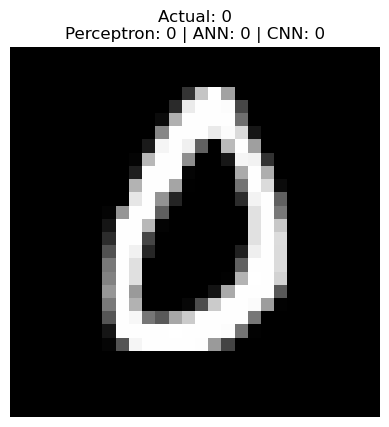

In [59]:
idx = np.random.randint(0, len(x_test))
img = x_test[idx]

p1 = perceptron.predict(img.reshape(1, 28, 28), verbose=0)
p2 = ann.predict(img.reshape(1, 28, 28), verbose=0)
p3 = cnn.predict(img.reshape(1, 28, 28, 1), verbose=0)

plt.imshow(img, cmap='gray')
plt.title(
    f"Actual: {y_test[idx]}\n"
    f"Perceptron: {np.argmax(p1)} | "
    f"ANN: {np.argmax(p2)} | "
    f"CNN: {np.argmax(p3)}"
)
plt.axis('off')
plt.show()

In [60]:
perceptron.save("perceptron.keras")
ann.save("ann.keras")
cnn.save("cnn.keras")
